# 1. Experiment Design & Power Analysis
**Project:** Checkout Flow Redesign A/B Test  
**Author:** Arik Rizki Akbar

### Context
The product team designed a streamlined single-page checkout flow to replace the legacy multi-step checkout. Before putting this live to traffic, we need to size the experiment:
- What sample size do we need to detect a meaningful effect?
- How long should the experiment run to avoid day-of-week seasonality?
- What are the primary, secondary, and guardrail metrics?


In [1]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sys.path.append(os.path.abspath("../src"))
from stats_utils import calculate_sample_size_per_variant

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 5.5)
plt.rcParams['font.size'] = 11


### Experiment Setup & Metrics

- **Primary Metric:** Checkout-to-purchase Conversion Rate (CR)
- **Secondary Metric:** Average Order Value (AOV) and Revenue per User (ARPU)
- **Guardrail Metric:** Payment error / gateway failure rate
- **Target MDE:** +1.5% absolute lift (+15% relative lift over baseline 10% CR)
- **Significance Level ($\\alpha$):** 0.05
- **Statistical Power ($1 - \\beta$):** 0.80
- **Daily Checkout Traffic:** ~6,000 sessions/day


In [2]:
baseline_cr = 0.10       # 10% baseline CR
mde_relative = 0.15      # +15% relative lift -> target 11.5% CR
alpha = 0.05             # 5% significance level
power = 0.80             # 80% statistical power

# Sizing per variant
required_n = calculate_sample_size_per_variant(
    baseline_cr=baseline_cr,
    mde_relative=mde_relative,
    alpha=alpha,
    power=power
)

total_n = required_n * 2
daily_traffic = 6000
est_days = int(np.ceil(total_n / daily_traffic))

print(f"Sample size per variant: {required_n:,}")
print(f"Total required sample  : {total_n:,}")
print(f"Estimated days required: {est_days} days (~{int(np.ceil(est_days / 7))} weeks)")


Sample size per variant: 6,693
Total required sample  : 13,386
Estimated days required: 3 days (~1 weeks)


### Sample Size vs. Minimum Detectable Effect (MDE)
Looking at how sample size requirements change if we target a smaller or larger effect:


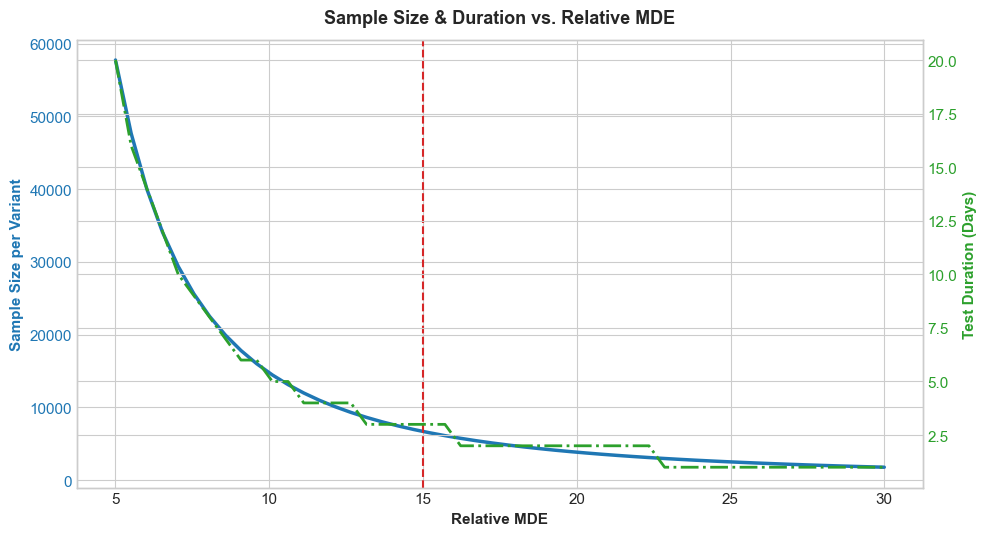

In [3]:
mde_range = np.linspace(0.05, 0.30, 50)
samples = [calculate_sample_size_per_variant(baseline_cr, m, alpha, power) for m in mde_range]
durations = [np.ceil((s * 2) / daily_traffic) for s in samples]

fig, ax1 = plt.subplots(figsize=(10, 5.5))

color = '#1f77b4'
ax1.set_xlabel('Relative MDE', fontweight='bold')
ax1.set_ylabel('Sample Size per Variant', color=color, fontweight='bold')
ax1.plot(mde_range * 100, samples, color=color, lw=2.5, label='Sample Size')
ax1.tick_params(axis='y', labelcolor=color)
ax1.axvline(15, color='#d62728', linestyle='--', lw=1.5, label='Target MDE (+15%)')

ax2 = ax1.twinx()
color = '#2ca02c'
ax2.set_ylabel('Test Duration (Days)', color=color, fontweight='bold')
ax2.plot(mde_range * 100, durations, color=color, lw=2, linestyle='-.', label='Duration (Days)')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Sample Size & Duration vs. Relative MDE', fontsize=13, fontweight='bold', pad=12)
fig.tight_layout()
os.makedirs("../reports/figures", exist_ok=True)
plt.savefig("../reports/figures/01_power_analysis_curve.png", dpi=300)
plt.show()


### Decision on Test Duration
We plan to run the test for **21 days (3 full weeks)**:
1. Reaches the required ~55,000 sessions per variant comfortably.
2. Captures full 7-day cycles to account for weekday vs weekend shopping behavior.
3. Strict rule: no early stopping (peeking) to prevent Type I error inflation.
